# 3D Brain Tumor Segmentation on BraTS2020 (MONAI 3D U-Net)

**Goal:** automatically segment glioma sub-regions from multi-sequence brain MRI.

**Data:** BraTS2020 training set, 369 patients. Each has four co-registered sequences (FLAIR, T1, T1ce, T2) and an expert segmentation mask with labels: necrotic/non-enhancing core, peritumoral edema and enhancing tumor.

**Approach:** 3D U-Net trained on 96×96×96 patches, evaluated on full volumes with sliding-window inference, using a patient-level train/validation/test split.

**Environment:** Kaggle notebook, GPU T4 x2, PyTorch + MONAI.

*Research project, not for clinical use.*

## 1. Setup and data exploration

Imports, dataset paths and a quick look at one patient. Each volume is 240×240×155 voxels, already co-registered and resampled by BraTS. The mask labels are 0 (background), 1 (necrotic core), 2 (edema) and 4 (enhancing tumor); there is no label 3.

MRI intensities have no fixed unit: the four sequences have very different ranges (for example T1ce up to about 1845 and T2 up to about 376 in the example patient), so they must be normalised before training.

In [ ]:
import os
root = "/kaggle/input"
print(os.listdir(root))

['datasets']


In [ ]:
import os
p = "/kaggle/input/datasets"
print(os.listdir(p))

['awsaf49']


In [ ]:
p = "/kaggle/input/datasets/awsaf49"
print(os.listdir(p))

['brats20-dataset-training-validation']


In [ ]:
path = "/kaggle/input/datasets/awsaf49/brats20-dataset-training-validation"
print(os.listdir(path))

['BraTS2020_ValidationData', 'BraTS2020_TrainingData']


In [ ]:
train = os.path.join(path, "BraTS2020_TrainingData")
print(os.listdir(train))

['MICCAI_BraTS2020_TrainingData']


In [ ]:
inner = os.path.join(train, "MICCAI_BraTS2020_TrainingData")
items = os.listdir(inner)
print(len(items))
print(items[:10])

371
['BraTS20_Training_083', 'BraTS20_Training_337', 'BraTS20_Training_161', 'BraTS20_Training_198', 'BraTS20_Training_284', 'BraTS20_Training_169', 'BraTS20_Training_157', 'BraTS20_Training_073', 'BraTS20_Training_253', 'BraTS20_Training_026']


In [ ]:
import pandas as pd

patient = os.path.join(inner, "BraTS20_Training_001")
print(os.listdir(patient))

print(pd.read_csv(os.path.join(inner, "name_mapping.csv")).head())
print(pd.read_csv(os.path.join(inner, "survival_info.csv")).head())

['BraTS20_Training_001_t2.nii', 'BraTS20_Training_001_t1ce.nii', 'BraTS20_Training_001_t1.nii', 'BraTS20_Training_001_seg.nii', 'BraTS20_Training_001_flair.nii']
  Grade BraTS_2017_subject_ID BraTS_2018_subject_ID TCGA_TCIA_subject_ID  \
0   HGG   Brats17_CBICA_AAB_1   Brats18_CBICA_AAB_1                  NaN   
1   HGG   Brats17_CBICA_AAG_1   Brats18_CBICA_AAG_1                  NaN   
2   HGG   Brats17_CBICA_AAL_1   Brats18_CBICA_AAL_1                  NaN   
3   HGG   Brats17_CBICA_AAP_1   Brats18_CBICA_AAP_1                  NaN   
4   HGG   Brats17_CBICA_ABB_1   Brats18_CBICA_ABB_1                  NaN   

  BraTS_2019_subject_ID BraTS_2020_subject_ID  
0   BraTS19_CBICA_AAB_1  BraTS20_Training_001  
1   BraTS19_CBICA_AAG_1  BraTS20_Training_002  
2   BraTS19_CBICA_AAL_1  BraTS20_Training_003  
3   BraTS19_CBICA_AAP_1  BraTS20_Training_004  
4   BraTS19_CBICA_ABB_1  BraTS20_Training_005  
              Brats20ID     Age Survival_days Extent_of_Resection
0  BraTS20_Training_001  60

(240, 240, 155) [0. 1. 2. 4.]


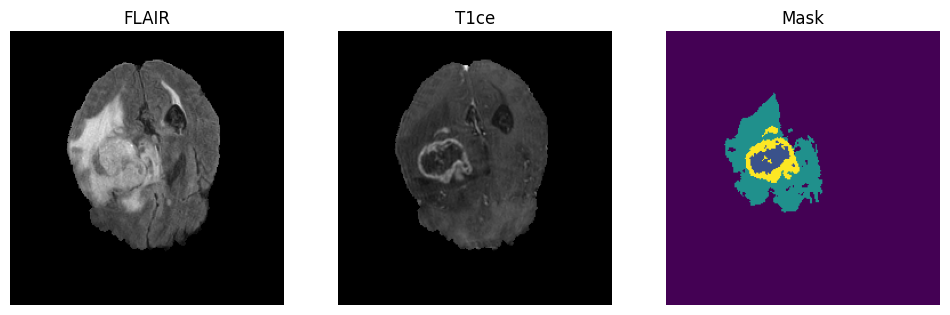

In [ ]:
!pip install -q nibabel
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

pid = "BraTS20_Training_001"
def load(seq):
    return nib.load(os.path.join(inner, pid, f"{pid}_{seq}.nii")).get_fdata()

flair, t1ce, seg = load("flair"), load("t1ce"), load("seg")
print(flair.shape, np.unique(seg))

z = seg.sum(axis=(0, 1)).argmax()   # slice with the most tumor
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, img, title in zip(ax, [flair[:, :, z], t1ce[:, :, z], seg[:, :, z]], ["FLAIR", "T1ce", "Mask"]):
    a.imshow(img.T, cmap="gray" if title != "Mask" else "viridis", origin="lower")
    a.set_title(title); a.axis("off")
plt.show()

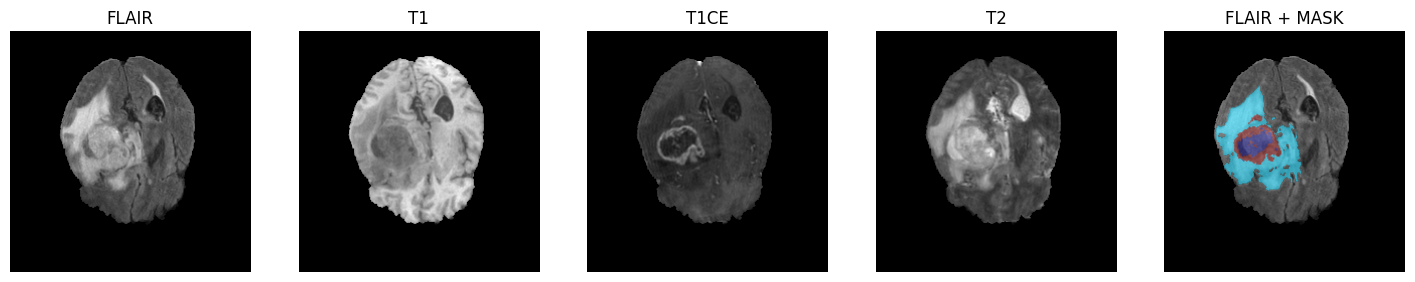

flair min 0.0 max 625.0 mean 26.0
t1 min 0.0 max 678.0 mean 53.3
t1ce min 0.0 max 1845.0 mean 62.8
t2 min 0.0 max 376.0 mean 17.3


In [ ]:
seqs = {s: load(s) for s in ["flair", "t1", "t1ce", "t2"]}

fig, ax = plt.subplots(1, 5, figsize=(18, 4))
for a, (name, vol) in zip(ax, seqs.items()):
    a.imshow(vol[:, :, z].T, cmap="gray", origin="lower")
    a.set_title(name.upper()); a.axis("off")
ax[4].imshow(seqs["flair"][:, :, z].T, cmap="gray", origin="lower")
ax[4].imshow(np.ma.masked_where(seg[:, :, z] == 0, seg[:, :, z]).T,
             cmap="jet", alpha=0.5, origin="lower")
ax[4].set_title("FLAIR + MASK"); ax[4].axis("off")
plt.show()

for name, vol in seqs.items():
    print(name, "min", vol.min(), "max", vol.max(), "mean", round(vol.mean(), 1))

### Intensity normalisation

For each patient and each sequence, only non-zero (brain) voxels are rescaled to mean 0 and standard deviation 1 (z-score). Background stays at 0. This stops scanner-dependent intensity scales from dominating what the model learns.

In [ ]:
def normalize(vol):
    brain = vol > 0
    out = np.zeros_like(vol, dtype=np.float32)
    mu, sd = vol[brain].mean(), vol[brain].std()
    out[brain] = (vol[brain] - mu) / (sd + 1e-8)
    return out

for name, vol in seqs.items():
    n = normalize(vol)
    brain = vol > 0
    print(name, "mean", round(n[brain].mean(), 3), "std", round(n[brain].std(), 3))

flair mean -0.0 std 1.0
t1 mean -0.0 std 1.0
t1ce mean -0.0 std 1.0
t2 mean -0.0 std 1.0


## 2. Patient-level train/validation/test split

The grade labels (HGG/LGG) come from `name_mapping.csv`. Of 369 patients, 293 are HGG and 76 are LGG.

The split is done **by patient, never by slice or patch**, so no patient appears in more than one set (this avoids data leakage, a common flaw in medical imaging projects). It is stratified by grade so each set has a similar HGG/LGG ratio.

| Set | Patients | HGG | LGG |
|---|---|---|---|
| Train | 258 | 205 | 53 |
| Validation | 55 | 44 | 11 |
| Test | 56 | 44 | 12 |

The `assert` checks confirm there is no overlap between sets.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# patient folders only (skips the two CSV files)
patients = sorted(d for d in os.listdir(inner)
                  if os.path.isdir(os.path.join(inner, d)))

# grade labels
nm = pd.read_csv(os.path.join(inner, "name_mapping.csv"))
df = (nm[["BraTS_2020_subject_ID", "Grade"]]
      .rename(columns={"BraTS_2020_subject_ID": "patient"}))
df = df[df["patient"].isin(patients)].reset_index(drop=True)

print(len(patients), len(df))
print(df["Grade"].value_counts())

# 70 / 15 / 15 split by patient, stratified by grade
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["Grade"], random_state=42)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["Grade"], random_state=42)

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(name, len(d), d["Grade"].value_counts().to_dict())

# no patient should appear in two sets
assert not set(train_df.patient) & set(val_df.patient)
assert not set(train_df.patient) & set(test_df.patient)
assert not set(val_df.patient) & set(test_df.patient)

369 369
Grade
HGG    293
LGG     76
Name: count, dtype: int64
train 258 {'HGG': 205, 'LGG': 53}
val 55 {'HGG': 44, 'LGG': 11}
test 56 {'HGG': 44, 'LGG': 12}


## 3. Data loading

A custom PyTorch `Dataset` that, for each patient:
1. loads the four sequences and normalises each one,
2. stacks them into a 4-channel input of shape (4, 240, 240, 155),
3. remaps label 4 to 3 so classes are consecutive (0, 1, 2, 3),
4. cuts out one random 96×96×96 patch.

Tumors occupy a small part of the volume, so random crops would be mostly background. In 70% of samples the patch is centred on a tumor voxel; in the other 30% it is centred randomly, so the model also sees healthy tissue.

A first batch has input shape (2, 4, 96, 96, 96) and mask shape (2, 96, 96, 96).

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

SEQS = ["flair", "t1", "t1ce", "t2"]

class BraTSDataset(Dataset):
    def __init__(self, patient_ids, patch=96, tumor_prob=0.7):
        self.ids = list(patient_ids)
        self.patch = patch
        self.tumor_prob = tumor_prob

    def __len__(self):
        return len(self.ids)

    def _read(self, pid, seq):
        f = os.path.join(inner, pid, f"{pid}_{seq}.nii")
        return nib.load(f).get_fdata().astype(np.float32)

    def __getitem__(self, i):
        pid = self.ids[i]
        img = np.stack([normalize(self._read(pid, s)) for s in SEQS])   # (4, 240, 240, 155)
        seg = self._read(pid, "seg").astype(np.int64)
        seg[seg == 4] = 3                                              # labels now 0,1,2,3

        # choose patch center: on a tumor voxel most of the time, else random
        if np.random.rand() < self.tumor_prob and seg.any():
            coords = np.argwhere(seg > 0)
            center = coords[np.random.randint(len(coords))]
        else:
            center = np.array([np.random.randint(s) for s in seg.shape])

        half = self.patch // 2
        sl = []
        for c, size in zip(center, seg.shape):
            start = int(np.clip(c - half, 0, size - self.patch))
            sl.append(slice(start, start + self.patch))
        sl = tuple(sl)

        return torch.from_numpy(img[(slice(None),) + sl]), torch.from_numpy(seg[sl])

train_ds = BraTSDataset(train_df.patient)
val_ds   = BraTSDataset(val_df.patient)

train_loader = DataLoader(train_ds, batch_size=2, shuffle=True, num_workers=2)

x, y = next(iter(train_loader))
print(x.shape, y.shape, x.dtype, y.dtype)
print("labels in this batch:", torch.unique(y))

torch.Size([2, 4, 96, 96, 96]) torch.Size([2, 96, 96, 96]) torch.float32 torch.int64
labels in this batch: tensor([0, 2, 3])


### Handling an oddly named mask file (patient 355)

While evaluating on the test set, the data loader crashed with a `FileNotFoundError`. In this Kaggle upload of BraTS2020, the segmentation mask for patient `BraTS20_Training_355` is named `W39_1998.09.19_Segm.nii` instead of `BraTS20_Training_355_seg.nii`, so the standard file path doesn't exist.

The fix below makes the loader fall back to the single file in the patient folder whose name contains "seg" when the standard name is missing. An `assert` stops the code with a clear message if there are zero or several candidates, so the wrong file is never loaded silently.

In [20]:
def _read(self, pid, seq):
    folder = os.path.join(inner, pid)
    f = os.path.join(folder, f"{pid}_{seq}.nii")
    if not os.path.exists(f) and seq == "seg":
        alt = [n for n in os.listdir(folder) if "seg" in n.lower()]
        assert len(alt) == 1, f"{pid}: expected one mask file, found {alt}"
        f = os.path.join(folder, alt[0])
        print("using mask file:", alt[0])
    return nib.load(f).get_fdata().astype(np.float32)

BraTSDataset._read = _read

In [ ]:
!pip install -q monai

import torch
from monai.networks.nets import UNet
from monai.losses import DiceCELoss

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

model = UNet(
    spatial_dims=3,                      # 3D volumes
    in_channels=4,                       # flair, t1, t1ce, t2
    out_channels=4,                      # background + 3 tumor classes
    channels=(16, 32, 64, 128, 256),     # feature maps at each depth
    strides=(2, 2, 2, 2),                # halve the size 4 times
    num_res_units=2,
).to(device)

loss_fn = DiceCELoss(to_onehot_y=True, softmax=True)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

print("parameters:", sum(p.numel() for p in model.parameters()))

# one forward pass to check everything fits together
x, y = next(iter(train_loader))
x, y = x.to(device), y.to(device)
with torch.no_grad():
    out = model(x)

print("input :", x.shape)
print("output:", out.shape)
print("loss  :", loss_fn(out, y.unsqueeze(1)).item())

device: cuda
parameters: 4811129
input : torch.Size([2, 4, 96, 96, 96])
output: torch.Size([2, 4, 96, 96, 96])
loss  : 2.492569923400879


## 4. Model: 3D U-Net (MONAI)

- **Architecture:** MONAI `UNet`, 3D, 4 input channels, 4 output classes, feature maps (16, 32, 64, 128, 256), 4 downsampling steps, 2 residual units per block. About 4.8 million parameters, small enough to train on a single T4.
- **Loss:** `DiceCELoss` (Dice + cross-entropy). Dice handles the class imbalance, since tumor voxels are a small fraction of the volume.
- **Optimiser:** AdamW, with mixed-precision (fp16) training to save memory.
- **Validation:** sliding-window inference over full volumes, reporting Dice for the three tumor classes (background excluded).

In [ ]:
import time
import torch.nn.functional as F
from torch.amp import autocast, GradScaler
from monai.inferers import sliding_window_inference
from monai.metrics import DiceMetric

# full-volume dataset for validation (no cropping)
class BraTSFull(BraTSDataset):
    def __getitem__(self, i):
        pid = self.ids[i]
        img = np.stack([normalize(self._read(pid, s)) for s in SEQS])
        seg = self._read(pid, "seg").astype(np.int64)
        seg[seg == 4] = 3
        return torch.from_numpy(img), torch.from_numpy(seg)

val_loader = DataLoader(BraTSFull(val_df.patient.iloc[:8]), batch_size=1, num_workers=2)
dice_metric = DiceMetric(include_background=False, reduction="mean_batch")

def validate():
    model.eval()
    dice_metric.reset()
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            with autocast("cuda"):
                out = sliding_window_inference(x, (96, 96, 96), 2, model, overlap=0.25)
            pred = F.one_hot(out.argmax(dim=1), 4).permute(0, 4, 1, 2, 3)
            true = F.one_hot(y, 4).permute(0, 4, 1, 2, 3)
            dice_metric(pred, true)
    model.train()
    return dice_metric.aggregate().cpu().numpy()   # Dice for classes 1, 2, 3

scaler = GradScaler("cuda")
EPOCHS, STEPS = 2, 30          # short test; we'll raise these for the real run
best = 0.0

for epoch in range(EPOCHS):
    t0, running = time.time(), 0.0
    model.train()
    for step, (x, y) in enumerate(train_loader):
        if step >= STEPS:
            break
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        with autocast("cuda"):
            loss = loss_fn(model(x), y.unsqueeze(1))
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running += loss.item()

    dice = validate()
    mean_dice = float(np.nanmean(dice))
    print(f"epoch {epoch+1} | loss {running/STEPS:.3f} | dice {np.round(dice, 3)} "
          f"| mean {mean_dice:.3f} | {time.time()-t0:.0f}s")

    if mean_dice > best:
        best = mean_dice
        torch.save(model.state_dict(), "/kaggle/working/best_model.pth")

epoch 1 | loss 1.750 | dice [0.155 0.302 0.078] | mean 0.178 | 68s
epoch 2 | loss 0.991 | dice [0.333 0.499 0.187] | mean 0.340 | 62s


 ## “Stage 1: initial training. Loss became NaN at epoch 6 (likely fp16 overflow at a high learning rate); the run was stopped and the best checkpoint (Dice 0.591) was kept.”

In [ ]:
EPOCHS, STEPS = 25, 100        # 25 x 100 steps, roughly 1 hour on a T4
history = []

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

for epoch in range(EPOCHS):
    t0, running = time.time(), 0.0
    model.train()
    for step, (x, y) in enumerate(train_loader):
        if step >= STEPS:
            break
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        with autocast("cuda"):
            loss = loss_fn(model(x), y.unsqueeze(1))
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running += loss.item()
    scheduler.step()

    dice = validate()
    mean_dice = float(np.nanmean(dice))
    history.append((epoch + 1, running / STEPS, *dice, mean_dice))
    print(f"epoch {epoch+1}/{EPOCHS} | loss {running/STEPS:.3f} | dice {np.round(dice, 3)} "
          f"| mean {mean_dice:.3f} | {time.time()-t0:.0f}s")

    if mean_dice > best:
        best = mean_dice
        torch.save(model.state_dict(), "/kaggle/working/best_model.pth")
        print("  saved new best")

epoch 1/25 | loss 0.756 | dice [0.409 0.618 0.385] | mean 0.471 | 160s
  saved new best
epoch 2/25 | loss 0.633 | dice [0.426 0.614 0.463] | mean 0.501 | 137s
  saved new best
epoch 3/25 | loss 0.588 | dice [0.519 0.635 0.354] | mean 0.503 | 132s
  saved new best
epoch 4/25 | loss 0.564 | dice [0.522 0.656 0.431] | mean 0.536 | 128s
  saved new best
epoch 5/25 | loss 0.525 | dice [0.567 0.614 0.451] | mean 0.544 | 127s
  saved new best
epoch 6/25 | loss nan | dice [0.623 0.689 0.461] | mean 0.591 | 126s
  saved new best
epoch 7/25 | loss nan | dice [0.185 0.302 0.08 ] | mean 0.189 | 126s
epoch 8/25 | loss nan | dice [0.004 0.075 0.   ] | mean 0.026 | 126s
epoch 9/25 | loss nan | dice [0. 0. 0.] | mean 0.000 | 123s
epoch 10/25 | loss nan | dice [0. 0. 0.] | mean 0.000 | 122s
epoch 11/25 | loss nan | dice [0. 0. 0.] | mean 0.000 | 125s
epoch 12/25 | loss nan | dice [0. 0. 0.] | mean 0.000 | 125s
epoch 13/25 | loss nan | dice [0. 0. 0.] | mean 0.000 | 126s


KeyboardInterrupt: 

In [ ]:
from torch.optim.lr_scheduler import CosineAnnealingLR

model.load_state_dict(torch.load("/kaggle/working/best_model.pth"))
model.to(device)
print("weights finite:", all(torch.isfinite(p).all().item() for p in model.parameters()))
print("best dice so far:", round(best, 3))

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-5)
EPOCHS, STEPS = 20, 100
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = GradScaler("cuda")
history = []

for epoch in range(EPOCHS):
    t0, running, used, skipped = time.time(), 0.0, 0, 0
    model.train()
    for step, (x, y) in enumerate(train_loader):
        if step >= STEPS:
            break
        x, y = x.to(device), y.to(device)

        if not torch.isfinite(x).all():          # bad input data
            skipped += 1
            continue

        optimizer.zero_grad()
        with autocast("cuda"):
            loss = loss_fn(model(x), y.unsqueeze(1))

        if not torch.isfinite(loss):             # bad loss, skip this batch
            skipped += 1
            continue

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        running += loss.item()
        used += 1
    scheduler.step()

    dice = validate()
    mean_dice = float(np.nanmean(dice))
    history.append((epoch + 1, running / max(used, 1), *dice, mean_dice))
    print(f"epoch {epoch+1}/{EPOCHS} | loss {running/max(used,1):.3f} | dice {np.round(dice, 3)} "
          f"| mean {mean_dice:.3f} | skipped {skipped} | {time.time()-t0:.0f}s")

    if mean_dice > best:
        best = mean_dice
        torch.save(model.state_dict(), "/kaggle/working/best_model.pth")
        print("  saved new best")

weights finite: True
best dice so far: 0.591
epoch 1/20 | loss 0.492 | dice [0.646 0.705 0.502] | mean 0.618 | skipped 1 | 123s
  saved new best
epoch 2/20 | loss 0.473 | dice [0.619 0.675 0.504] | mean 0.599 | skipped 0 | 132s
epoch 3/20 | loss 0.461 | dice [0.641 0.702 0.494] | mean 0.613 | skipped 0 | 127s
epoch 4/20 | loss 0.483 | dice [0.634 0.71  0.451] | mean 0.598 | skipped 0 | 126s
epoch 5/20 | loss 0.472 | dice [0.692 0.709 0.492] | mean 0.631 | skipped 0 | 126s
  saved new best
epoch 6/20 | loss 0.481 | dice [0.673 0.705 0.501] | mean 0.626 | skipped 0 | 126s
epoch 7/20 | loss 0.465 | dice [0.697 0.72  0.499] | mean 0.639 | skipped 0 | 124s
  saved new best
epoch 8/20 | loss 0.466 | dice [0.667 0.719 0.486] | mean 0.624 | skipped 0 | 122s
epoch 9/20 | loss 0.446 | dice [0.738 0.732 0.493] | mean 0.654 | skipped 0 | 124s
  saved new best
epoch 10/20 | loss 0.429 | dice [0.658 0.717 0.505] | mean 0.627 | skipped 0 | 126s
epoch 11/20 | loss 0.451 | dice [0.698 0.727 0.488] | me

## 7. Evaluation on the held-out test set

The best checkpoint is evaluated on the 56 test patients, who were never used for training or for choosing the checkpoint. Scores use the standard BraTS regions:
- **WT** (whole tumor): labels 1, 2, 3
- **TC** (tumor core): labels 1 and 3
- **ET** (enhancing tumor): label 3

| Region | Mean Dice |
|---|---|
| WT | 0.868 |
| TC | 0.784 |
| ET | 0.790 |

| Grade | WT | TC | ET |
|---|---|---|---|
| HGG | 0.875 | 0.840 | 0.838 |
| LGG | 0.840 | 0.582 | 0.529 |

Four test patients have no enhancing tumor in the ground truth and are excluded from the ET average.

In [21]:
model.load_state_dict(torch.load("/kaggle/working/best_model.pth"))
model.eval()
test_loader = DataLoader(BraTSFull(test_df.patient), batch_size=1, num_workers=2)

def dice(p, t):
    if t.sum() == 0:                  # no such region in the ground truth
        return np.nan
    return (2 * (p & t).sum() / (p.sum() + t.sum())).item()

regions = {"WT": lambda m: m > 0,
           "TC": lambda m: (m == 1) | (m == 3),
           "ET": lambda m: m == 3}

rows = []
with torch.no_grad():
    for (x, y), pid in zip(test_loader, test_df.patient):
        x, y = x.to(device), y.to(device)
        with autocast("cuda"):
            out = sliding_window_inference(x, (96, 96, 96), 2, model, overlap=0.25)
        pred, truth = out.argmax(dim=1)[0], y[0]
        rows.append({"patient": pid,
                     **{k: dice(f(pred), f(truth)) for k, f in regions.items()}})

res = pd.DataFrame(rows).merge(test_df, on="patient")
print(res[["WT", "TC", "ET"]].mean().round(3))
print(res.groupby("Grade")[["WT", "TC", "ET"]].mean().round(3))
print("patients with no ET in ground truth:", res["ET"].isna().sum())
res.to_csv("/kaggle/working/test_results.csv", index=False)

using mask file: W39_1998.09.19_Segm.nii
WT    0.868
TC    0.784
ET    0.790
dtype: float64
          WT     TC     ET
Grade                     
HGG    0.875  0.840  0.838
LGG    0.840  0.582  0.529
patients with no ET in ground truth: 4


## 8. Learning curves and predictions

The learning curves show stage 2 (fine-tuning) only. The prediction figure shows the best, median and worst test patients by whole-tumor Dice, each with FLAIR, the expert mask and the model's prediction. Colours: cyan = necrotic core, yellow = edema, dark red = enhancing tumor.



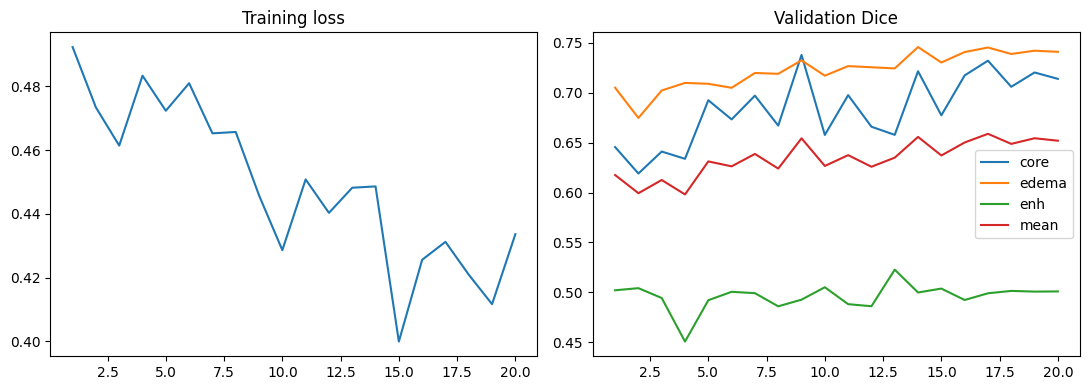

using mask file: W39_1998.09.19_Segm.nii


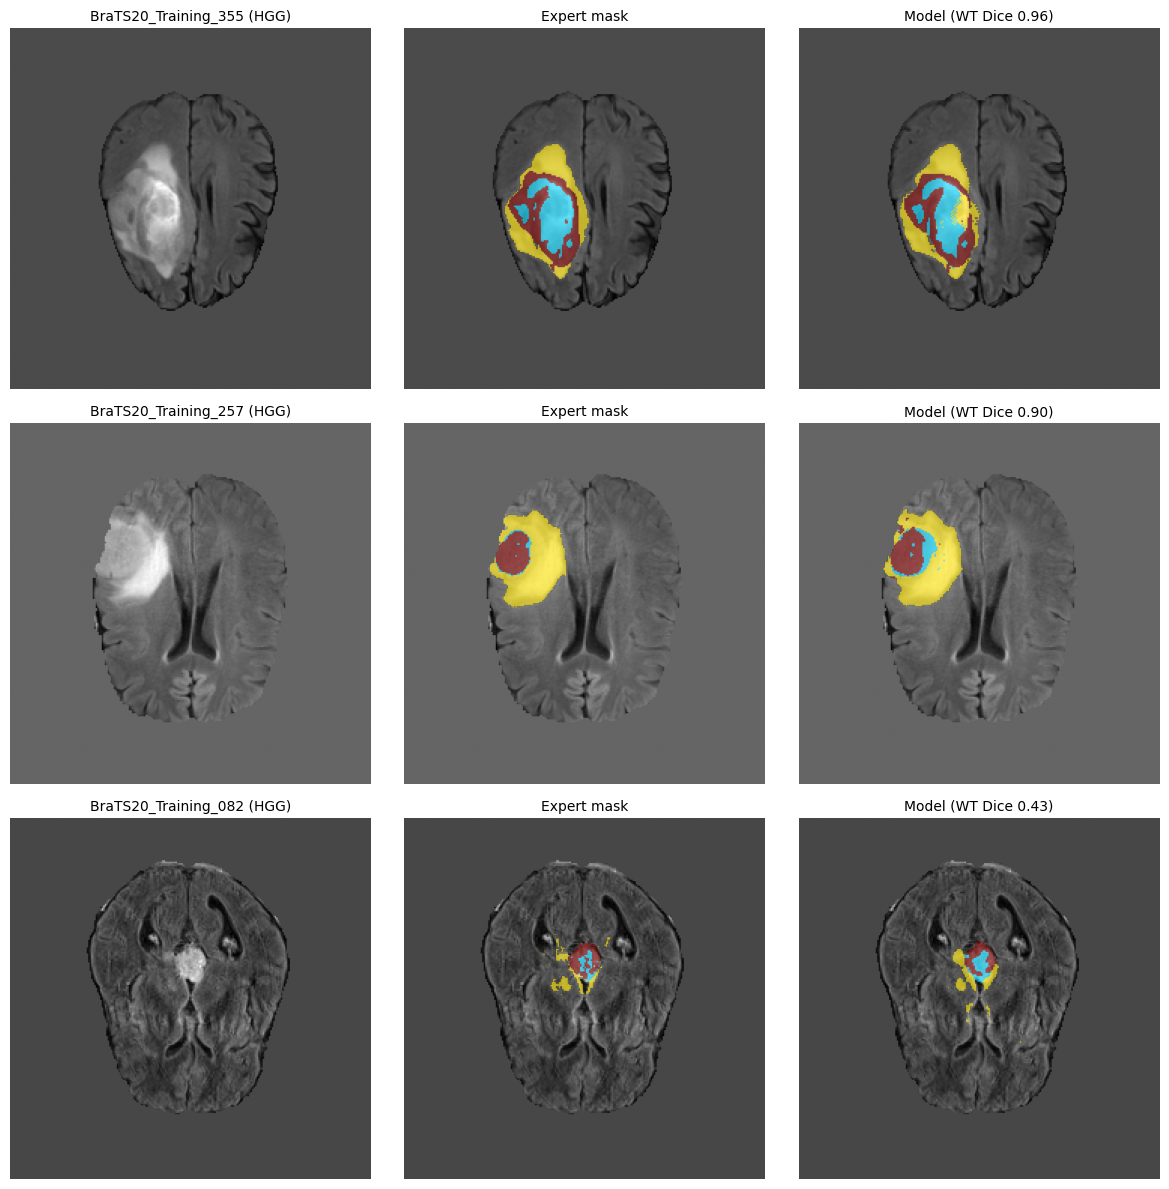

In [22]:
# learning curves (from the 20 fine-tuning epochs)
h = pd.DataFrame(history, columns=["epoch", "loss", "core", "edema", "enh", "mean"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h.epoch, h.loss); ax[0].set_title("Training loss")
for c in ["core", "edema", "enh", "mean"]:
    ax[1].plot(h.epoch, h[c], label=c)
ax[1].set_title("Validation Dice"); ax[1].legend()
plt.tight_layout(); plt.savefig("/kaggle/working/curves.png", dpi=150); plt.show()

# predictions vs expert
order = res.sort_values("WT").reset_index(drop=True)
picks = [order.iloc[-1], order.iloc[len(order) // 2], order.iloc[0]]

fig, ax = plt.subplots(3, 3, figsize=(12, 12))
for r, row in enumerate(picks):
    x, y = BraTSFull([row.patient])[0]
    with torch.no_grad(), autocast("cuda"):
        out = sliding_window_inference(x[None].to(device), (96, 96, 96), 2, model, overlap=0.25)
    pred, truth = out.argmax(1)[0].cpu().numpy(), y.numpy()
    z = (truth > 0).sum(axis=(0, 1)).argmax()
    flair = x[0].numpy()[:, :, z].T
    titles = [f"{row.patient} ({row.Grade})", "Expert mask", f"Model (WT Dice {row.WT:.2f})"]
    ax[r, 0].imshow(flair, cmap="gray", origin="lower")
    for a, m in [(ax[r, 1], truth[:, :, z]), (ax[r, 2], pred[:, :, z])]:
        a.imshow(flair, cmap="gray", origin="lower")
        a.imshow(np.ma.masked_where(m.T == 0, m.T), cmap="jet", vmin=0, vmax=3, alpha=0.6, origin="lower")
    for a, t in zip(ax[r], titles):
        a.set_title(t, fontsize=10); a.axis("off")
plt.tight_layout(); plt.savefig("/kaggle/working/predictions.png", dpi=150); plt.show()

## 9. Limitations and next steps

- Results come from a single split of 56 test patients; a different split could shift scores by a few points. The validation set (8 patients used for checkpoint selection) is small and noisy.
- Low-grade glioma performance is clearly weaker (TC 0.58, ET 0.53), likely because LGG is under-represented (53 training patients) and often shows little enhancement. This is a hypothesis, not tested here.
- False positives on patients with no enhancing tumor were not measured.
- Small model, about 2 hours of training in total, with no ensembling or test-time augmentation, so scores are below published BraTS challenge winners.
- Next steps: class-balanced sampling for LGG, longer training, and testing generalisation on BraTS-Africa.